In [10]:
import re, sys
import polars as pl
from pathlib import Path
from plotnine import *
from pprint import pprint

import phonopy
from phonopy import alignment
from phonopy.strings import str_standardize

In [11]:
# Pronunciation dictionary.
data_dir = Path.home() / "Languages/00Dictionaries/wikipron/data/scrape/tsv"
data_file = "ceb_latn_broad.tsv"

data_df = pl.read_csv(data_dir / data_file, separator="\t", has_header=False, new_columns=["orth", "phon"])
print(data_df.shape)
print(data_df.head())

(2953, 2)
shape: (5, 2)
┌──────────┬───────────────────┐
│ orth     ┆ phon              │
│ ---      ┆ ---               │
│ str      ┆ str               │
╞══════════╪═══════════════════╡
│ Abapo    ┆ ʔ a b a p o       │
│ Abayon   ┆ ʔ a b a j o n     │
│ Abello   ┆ ʔ a b e l j o     │
│ Abesamis ┆ ʔ a b e s a m i s │
│ Abril    ┆ ʔ a b ɾ i l       │
└──────────┴───────────────────┘


In [12]:
aligner = alignment.SelfAligner()

alignments = []
for idx, x in enumerate(data_df["phon"].to_list()):
    x = str_standardize(x)
    try:
        align = aligner.get_alignment(x)
        align_best = align[0]
        align_str = aligner.markup_self_alignment( \
            x, align_best.alignment, align_best.offset)
        align_score = align_best[0]
        alignments.append((align_score, align_str))
    except:
        print(f"Error aligning {x}")
        alignments.append((None, None))
    if idx > 1000:
        break

Error aligning b a n t aː j a n
Error aligning s ɛ b uː
Error aligning ɛː n a d
Error aligning ʔ ɪ n tʃ i k
Error aligning l a p u l aˑ p u
Error aligning s a n tʃ a ŋ k o
Error aligning b iː n̪ ʊ s
Error aligning b i s̺ a j a ʔ
Error aligning a b ʊ t̪
Error aligning ʔ a dʒ a w
Error aligning a l̪ i m p o
Error aligning a l̪ i m p u d ʒ o
Error aligning a l̪ i m p u l̪ o
Error aligning ʔ a l i m p u dʒ o s
Error aligning ʔ a dʒ a m
Error aligning ʔ a dʒ a w
Error aligning b aː
Error aligning b a b a dʒ e
Error aligning b a l̪ a d ʒ a
Error aligning b a l̪ a j a
Error aligning b a l̪ a ɪ ə
Error aligning b a l̪ i
Error aligning b a l̪ i ʔ
Error aligning b a l̪ u ŋ b o ŋ
Error aligning b a n aˑ w a ʔ
Error aligning b a n t̺ a ʔ
Error aligning b a dʒ a b a s
Error aligning b a dʒ a d
Error aligning b i b i h a n̪
Error aligning b i n̪ a l̪ i
Error aligning b i n̪ a l̪ i ʔ
Error aligning d aː t u ʔ
Error aligning d a dʒ o


In [16]:
alignments_df = pl.DataFrame(alignments, orient="row", schema=["score", "alignment"])

/home/colin/Applications/miniconda3/envs/py3_14/lib/python3.14/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 33 rows containing non-finite values.


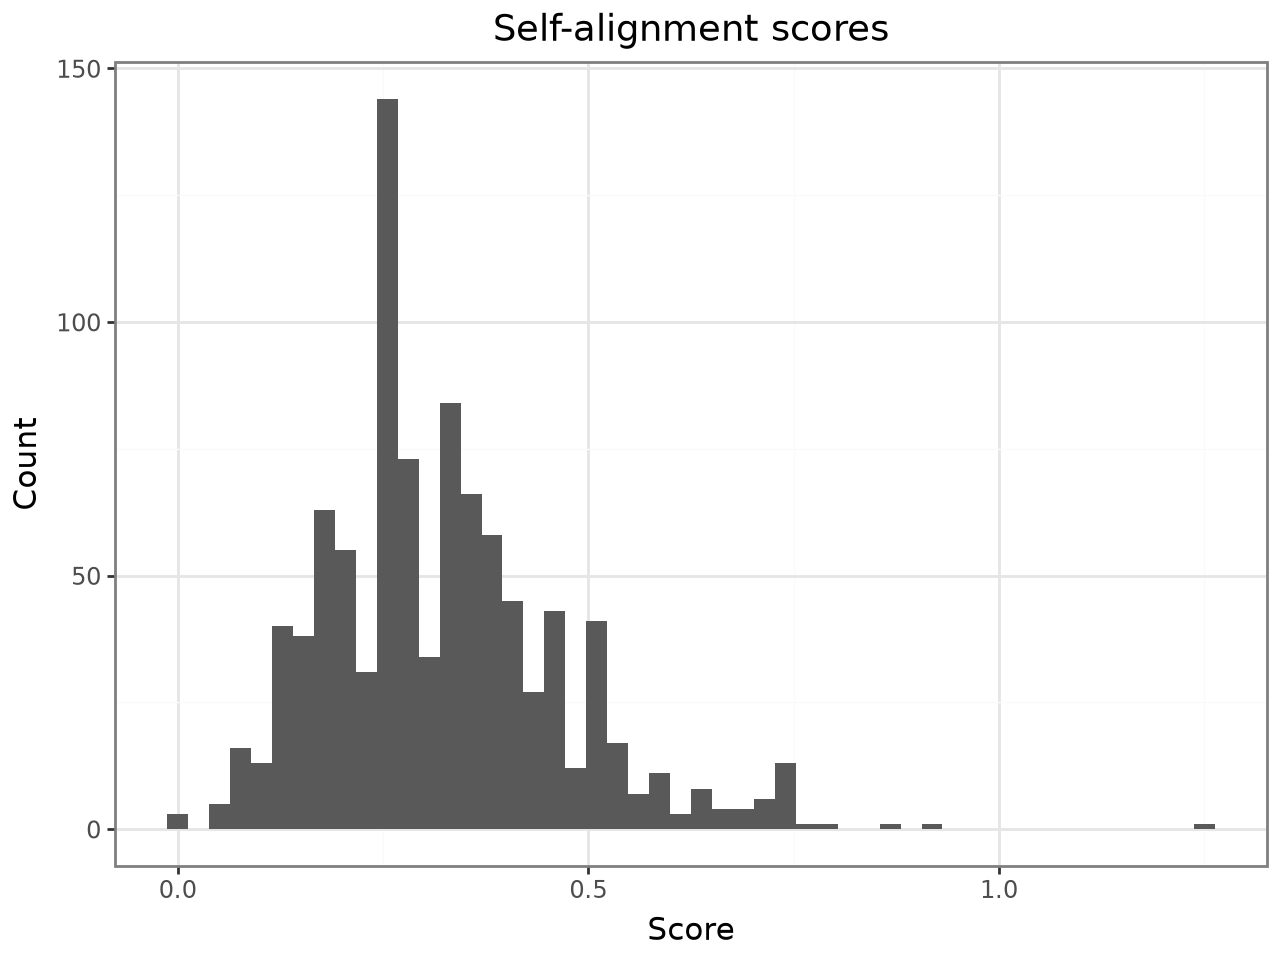

In [17]:
ggplot(alignments_df, aes(x="score")) + geom_histogram(bins=50) + theme_bw() + labs(title="Self-alignment scores", x="Score", y="Count")

In [19]:
alignments_df.filter(pl.col("score") > 0.75)

score,alignment
f64,str
0.858105,"""ʔ ⟨ a b e s ⟩ ⟨ a m i s ⟩"""
0.75,"""⟨ k a ɾ ⟩ ⟨ k a ɾ ⟩"""
0.930545,"""⟨ k a b a n ⟩ ⟨ k a l a n ⟩"""
0.75,"""⟨ p i l ⟩ a ⟨ p i l ⟩"""
0.75,"""ʔ a l i ⟨ b a ŋ ⟩ ⟨ b a ŋ ⟩"""
…,…
0.75,"""⟨ b a j ⟩ ⟨ b a j ⟩"""
0.75,"""b i ⟨ k a ŋ ⟩ ⟨ k a ŋ ⟩"""
0.75,"""⟨ b i t ⟩ ⟨ b i t ⟩"""
